# Lab 3
# Parametric classification
# ---------------------------------------------------

<h2>Table of contents </h2>

<div class="alert alert-block alert-info" style="margin-top: 20px">
<ol>
    <li> Introduction</li>
    <li> Simple logistic regression  </li>
    <li> Multivariable logistic regression </li>
    <li> Logistic regression with regularization </li>
    <li> Comparison of the results obtained with the different models </li>
</ol>

</div>

<hr>


## 1. Introduction

Assume that you want to design a parametric classification model on a set of observation, where each observation is described in terms of a set of variables. Without knowing anything else about the data set, provide a reasoned justification:

(a) Explain in your own words what is the main difference between supervised learning methods and unsupervised learning methods.  Give an example of application of each type of method. Briefly describe the input and output variables you would consider in each example.

b) Explain in your own words the main difference between soft and hard output of a learning model. Indicate which of the methods presented in theory provide a soft output and which provide a hard output.

c) Explain the concept of overfitting and generalization. If you wish, you may support your answer with a diagram or drawing. Explain in your own words how you could make the designed model generalize well.



**a) Supervised vs. unsupervised.** In **supervised** learning every training observation comes with a known output (label or target value) and the model learns the mapping input → output, so its error can be measured by comparing predictions with the true outputs. In **unsupervised** learning there is no output: the algorithm only sees the inputs and looks for structure (groups, patterns, lower-dimensional representations).

* *Supervised example (this lab):* classify a patient as **diabetic / non-diabetic** (output `Outcome`, binary → classification) from glucose, BMI, age, number of pregnancies, blood pressure, insulin, skin thickness and diabetes pedigree function (inputs). If the output were a continuous value (e.g. glucose, Lab 2) it would be regression.
* *Unsupervised example:* **clustering** (K-means) the same patients using only the clinical measurements to discover phenotypes / risk profiles. There is no output variable, so the clusters must be interpreted afterwards.

**b) Soft vs. hard output.** The **hard output** is directly the predicted class (here 0 or 1). The **soft output** is a continuous score that expresses how confident the model is, typically an estimate of the posterior probability $P(y=1\,|\,\mathbf{x})$. The hard output is obtained from the soft one with a decision threshold (usually 0.5): $\hat y = 1$ if $P(y=1|\mathbf{x}) \geq 0.5$.
* **Logistic regression** gives a **soft output** by construction: $P(y=1|\mathbf{x}) = \sigma(w_0 + \mathbf{w}^T\mathbf{x})$ with $\sigma(z)=1/(1+e^{-z})$, and the hard output comes from thresholding it. Having a soft output is what allows us to draw the **ROC curve** (sweeping the threshold) and to move the operating point towards more sensitivity or more specificity.
* Other methods that give a soft output: LDA/QDA and naive Bayes (posterior probabilities), and, in Lab 4, k-NN (fraction of neighbours of each class), trees (class proportion in the leaf), ensembles and neural networks. Methods such as the perceptron or a plain SVM only give a hard output (or a score that is not a probability).

**c) Overfitting and generalization.** **Generalization** is the ability of the model to predict well observations it has *not* seen during training; this is what we really care about. **Overfitting** happens when the model is too flexible for the amount of data and, besides the pattern, it learns the noise of the training set: training error is very low, but test error is much higher (large gap between both). The opposite problem is *underfitting* (too rigid a model: both errors high). It is the **bias–variance trade-off**: flexibility lowers the bias but increases the variance.

To obtain a model that generalizes well: (1) never evaluate on the data used for training: separate a **test set** and use **cross-validation** on the training set to choose hyper-parameters; (2) **regularization** (Ridge/Lasso) to limit the size of the coefficients; (3) reduce the number of variables (feature selection) and use simpler models; (4) get more data; (5) preprocess correctly (e.g. fit the scaler only with the training set, to avoid information leakage).

For the development of this first practice we will analyze the "Pima Indian Diabetes" database already preprocessed, where the rows of the file correspond to the observations and the columns to the variables.

For this practice, the data will be divided into two subsets: training and test. In addition, the validation scheme called k-fold cross-validation will be considered.

In [1]:
from sklearn.model_selection import cross_val_score
from sklearn import model_selection
from sklearn.model_selection import KFold, StratifiedKFold, cross_val_score, train_test_split
from sklearn import metrics
from sklearn.pipeline import make_pipeline

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib
from matplotlib import pyplot as plt
import warnings
warnings.filterwarnings("ignore")

In [2]:
# Load the dataset (already preprocessed at the end of Lab 1: the impossible zeros of Glucose, BloodPressure,
# SkinThickness, Insulin and BMI were replaced by the mean of the valid values).
# Relative path: the csv is in LAB1/Lab1_Material of this repository (run the notebook from the LAB3 folder).
df = pd.read_csv("../LAB1/Lab1_Material/pima_preprocessed.csv")
print(df.shape)
df.head()

(768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148.0,72.0,35.00000,155.548223,33.6,0.627,50,1
1,1,85.0,66.0,29.00000,155.548223,26.6,0.351,31,0
2,8,183.0,64.0,29.15342,155.548223,23.3,0.672,32,1
3,1,89.0,66.0,23.00000,94.000000,28.1,0.167,21,0
4,0,137.0,40.0,35.00000,168.000000,43.1,2.288,33,1


In [3]:
# Input X = all the variables except the output. Output y = Outcome (0 = non-diabetic, 1 = diabetic)
# Note: here the output is the diagnosis, so Glucose is a legitimate input (in Lab 2 it was the output).
X = df.drop(columns='Outcome')
y = df['Outcome']

# We define the training set (80% of the observations) and test set (20% of the observations).
# random_state -> always the same split. stratify=y -> both sets keep the same proportion of diabetic patients
# (important with imbalanced classes).
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("X_train:", X_train.shape, " X_test:", X_test.shape)
print("%% of diabetic patients -> all data: %.1f | train: %.1f | test: %.1f" % (100*y.mean(), 100*y_train.mean(), 100*y_test.mean()))

X_train: (614, 8)  X_test: (154, 8)
% of diabetic patients -> all data: 34.9 | train: 34.9 | test: 35.1


In [4]:
# Show the first rows of the input
X.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
0,6,148.0,72.0,35.00000,155.548223,33.6,0.627,50
1,1,85.0,66.0,29.00000,155.548223,26.6,0.351,31
2,8,183.0,64.0,29.15342,155.548223,23.3,0.672,32
3,1,89.0,66.0,23.00000,94.000000,28.1,0.167,21
4,0,137.0,40.0,35.00000,168.000000,43.1,2.288,33


In [5]:
# Show the first rows of the output
y.head()

0    1
1    0
2    1
3    0
4    1
Name: Outcome, dtype: int64

In [6]:
# Show the first rows of the X_train
X_train.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
353,1,90.0,62.0,12.00000,43.000000,27.2,0.580,24
711,5,126.0,78.0,27.00000,22.000000,29.6,0.439,40
373,2,105.0,58.0,40.00000,94.000000,34.9,0.225,25
46,1,146.0,56.0,29.15342,155.548223,29.7,0.564,29
682,0,95.0,64.0,39.00000,105.000000,44.6,0.366,22


#### Define the figure of merit, for example, accuracy, sensitivity, specificity, ROC-AUC

In [7]:
from sklearn.metrics import confusion_matrix, accuracy_score, recall_score, classification_report, roc_auc_score, roc_curve

# Lists to store the results of every model on the TEST set
model_names = []
accuracy = []
sensitivity = []
specificty = []
auc = []

# 5-fold stratified cross-validation on the TRAINING set (shuffled, fixed seed -> reproducible)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

def classification_metrics(y_true, y_pred, y_prob):
    """Return accuracy, sensitivity, specificity, PPV (precision), F1 and AUC."""
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    acc = (tp + tn) / (tn + fp + fn + tp)
    sen = tp / (tp + fn)                      # recall / true positive rate
    spe = tn / (tn + fp)                      # true negative rate
    ppv = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    f1 = 2 * ppv * sen / (ppv + sen) if (ppv + sen) > 0 else 0.0
    return acc, sen, spe, ppv, f1, roc_auc_score(y_true, y_prob)

def evaluate(name, model, Xte, yte, store=True, verbose=True):
    """Predict on the test set, print the confusion matrix and the figures of merit, and store them."""
    y_pred = model.predict(Xte)                  # hard output (0/1, threshold 0.5)
    y_prob = model.predict_proba(Xte)[:, 1]      # soft output P(Outcome = 1)
    acc, sen, spe, ppv, f1, auc_ = classification_metrics(yte, y_pred, y_prob)
    if verbose:
        print(name)
        print(confusion_matrix(yte, y_pred))
        print(f"Accuracy: {acc:.3f} | Sensitivity: {sen:.3f} | Specificity: {spe:.3f} | PPV: {ppv:.3f} | F1: {f1:.3f} | AUC: {auc_:.3f}")
    if store:
        model_names.append(name); accuracy.append(acc); sensitivity.append(sen); specificty.append(spe); auc.append(auc_)
    return y_prob

def plot_roc(yte, y_prob, title='Receiver Operating Characteristic'):
    fpr, tpr, _ = roc_curve(yte, y_prob)
    roc_auc = roc_auc_score(yte, y_prob)
    plt.title(title)
    plt.plot(fpr, tpr, 'b', label='AUC = %0.2f' % roc_auc)
    plt.legend(loc='lower right')
    plt.plot([0, 1], [0, 1], 'r--')
    plt.xlim([0, 1]); plt.ylim([0, 1])
    plt.ylabel('True Positive Rate'); plt.xlabel('False Positive Rate')
    plt.show()

**Figures of merit.** All of them are computed from the **confusion matrix** (rows = true class, columns = predicted class; positive = diabetic): TP, FN, FP, TN.

| Figure | Formula | Meaning |
|---|---|---|
| Accuracy | (TP+TN) / all | fraction of correct predictions |
| Sensitivity (recall, TPR) | TP / (TP+FN) | fraction of diabetic patients that we detect |
| Specificity (TNR) | TN / (TN+FP) | fraction of healthy patients correctly cleared |
| PPV (precision) | TP / (TP+FP) | if the model says "diabetic", probability of being right |
| F1 | 2·PPV·Sens / (PPV+Sens) | harmonic mean of precision and sensitivity |
| AUC | area under the ROC curve | quality of the **soft output**, independent of the threshold: probability that a random diabetic patient gets a higher score than a random healthy one |

**Why accuracy alone is not enough here.** The classes are imbalanced (65 % / 35 %): a "classifier" that always answers *non-diabetic* gets **64.9 % accuracy on the test set** with sensitivity 0. That is the baseline that any model must beat. That is why we always report sensitivity and specificity (clinically, missing a diabetic patient = false negative is usually worse than a false alarm) and the AUC, which does not depend on the 0.5 threshold. The partition is **stratified** so that train and test keep the same proportion of diabetic patients (≈35 %), and the validation of hyper-parameters is made with **stratified 5-fold cross-validation on the training set only**.

## 2.  Logistic regression

## 2.  Logistic regression


(a) Design a logistic regression model using the training and test subsets described above. Clearly indicate what the desired output is.

b) Comment on the confusion matrix as well as the results obtained in terms of at least two figure of merit.

c) Indicate if the figure of merit obtained in the test set change after normalizing the variables.

d) Justify which features are more relevant in this case.


In [8]:
from sklearn import model_selection   
from sklearn import metrics
from sklearn.linear_model import LogisticRegression

# Logistic regression
lg_regression = LogisticRegression()

# Train the model using X_train using only the feature 'Age' as the input
regressor = lg_regression.fit(np.array(X_train['Age']).reshape(-1, 1), y_train)

# Show the intercept
print(f'Intercept: {regressor.intercept_}')

# Show the coefficients
print(f'Coefficients: {regressor.coef_}')

# Predict the values using the test set. Obtain both the hard and the soft output
X_test_age = np.array(X_test['Age']).reshape(-1, 1)
y_pred = regressor.predict(X_test_age)               # hard output (0/1)
y_prob_pred = regressor.predict_proba(X_test_age)[:, 1]  # soft output P(Outcome=1)

print(f'Y_pred: {y_pred} ')
print(f'y_prob_pred: {y_prob_pred} ')



Intercept: [-2.06172899]
Coefficients: [[0.04222087]]
Y_pred: [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 1 1 0 1 1 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 1 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0
 0 1 0 0 0 1 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 1 0 0 0 0 1 0 0 1
 0 0 0 0 0 0] 
y_prob_pred: [0.40784189 0.48067263 0.27608078 0.34836828 0.24363188 0.29327216
 0.45964056 0.39768628 0.23593605 0.27608078 0.24363188 0.27608078
 0.23593605 0.23593605 0.26772276 0.38761802 0.55433412 0.24363188
 0.34836828 0.32019366 0.56473928 0.60570709 0.32019366 0.50177342
 0.5228679  0.36777416 0.35801306 0.23593605 0.42838279 0.23593605
 0.24363188 0.24363188 0.29327216 0.2514961  0.28459831 0.2514961
 0.30209874 0.2514961  0.28459831 0.50177342 0.47014334 0.47014334
 0.24363188 0.35801306 0.25952707 0.55433412 0.30209874 0.29327216
 0.24363188 0.2514961  0.42838279 0.32019366 0.27608078 0.25952707
 0.39768

**a) Desired output.** The output is **`Outcome`** (0 = non-diabetic, 1 = diabetic), a binary variable, so we need a *classification* model. The simple logistic regression models the **log-odds** as a linear function of one input: $\ln\frac{p}{1-p} = w_0 + w_1\,Age$, i.e. $p = P(Outcome=1|Age)=\sigma(w_0+w_1 Age)$. The parameters are estimated by **maximum likelihood** (equivalently, minimizing the cross-entropy / log-loss; there is no closed-form solution as in linear regression, so it is solved iteratively).

Here $w_0 = -2.06$ and $w_1 = 0.042$: each additional year multiplies the **odds** of diabetes by $e^{0.042} \approx 1.04$ (+4 %). The soft output (`y_prob_pred`) goes from 0.24 to 0.69 and only a few patients exceed 0.5, so the hard output is 0 for most of them.

In [9]:
from sklearn.metrics import confusion_matrix
from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report
from sklearn.metrics import recall_score

#  Compute the confusion matrix
cm = confusion_matrix(y_test, y_pred)
print(cm)

tn, fp, fn, tp = cm.ravel()
print(f'tn: {tn}, fp:{fp}, fn:{fn}, tp:{tp}')

# Compute the accuracy
Accuracy = accuracy_score(y_test, y_pred)
print(f'Accuracy: {Accuracy}')

#Sensibility (sensitivity = recall of the positive class = tp / (tp + fn))
Sensibility = recall_score(y_test, y_pred)
print(f'Sensibility: {Sensibility}')

# Specificity = tn / (tn + fp)
Specificity = tn / (tn + fp)
print(f'Specificity: {Specificity}')

print(classification_report(y_test, y_pred))

[[90 10]
 [46  8]]
tn: 90, fp:10, fn:46, tp:8
Accuracy: 0.6363636363636364
Sensibility: 0.14814814814814814
Specificity: 0.9
              precision    recall  f1-score   support

           0       0.66      0.90      0.76       100
           1       0.44      0.15      0.22        54

    accuracy                           0.64       154
   macro avg       0.55      0.52      0.49       154
weighted avg       0.59      0.64      0.57       154



AUC: 0.71


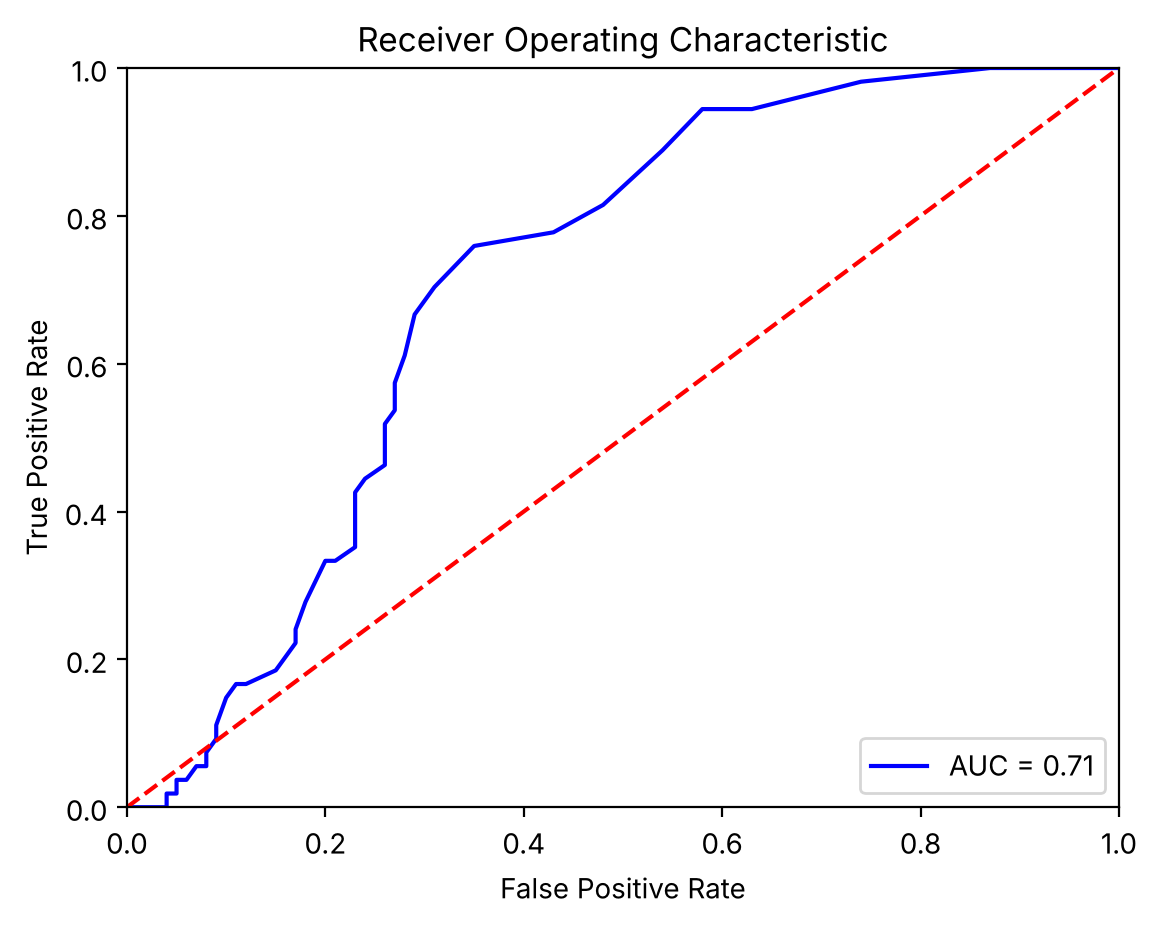

In [10]:
# Compute the AUC and the ROC
fpr, tpr, thresholds = roc_curve(y_test, y_prob_pred)
roc_auc = roc_auc_score(y_test, y_prob_pred)
print("AUC:", round(roc_auc, 3))

# Plot the ROC curve
import matplotlib.pyplot as plt
plt.title('Receiver Operating Characteristic')
plt.plot(fpr, tpr, 'b', label = 'AUC = %0.2f' % roc_auc)
plt.legend(loc = 'lower right')
plt.plot([0, 1], [0, 1],'r--')
plt.xlim([0, 1])
plt.ylim([0, 1])
plt.ylabel('True Positive Rate')
plt.xlabel('False Positive Rate')
plt.show()

# Store the results of this model
model_names.append("LR - Age"); accuracy.append(Accuracy); sensitivity.append(Sensibility)
specificty.append(Specificity); auc.append(roc_auc)

**b) Confusion matrix and figures of merit (Age only).** On the test set (154 patients, 54 diabetic): TN = 90, FP = 10, FN = 46, TP = 8.
* **Accuracy = 0.636**, which is *lower* than the trivial classifier that always says "non-diabetic" (0.649).
* **Sensitivity = 0.148** (we detect only 8 of 54 diabetic patients) and **specificity = 0.90**.
* **AUC = 0.71**: the *ranking* given by the soft output is informative (better than 0.5), but the *hard* decision is poor.

The reason is that Age alone is a weak predictor and the prior probability of diabetes is only 0.35, so the estimated probabilities rarely exceed the 0.5 threshold: the model almost always answers "healthy". The problem is not the model's ranking but the **threshold** (see the threshold analysis in Section 3) and, above all, the lack of information in one variable.

In [11]:
# Which single feature is the best predictor? Simple LR with each feature, AUC with 5-fold CV on the TRAINING set
single = {}
for col in X.columns:
    single[col] = cross_val_score(LogisticRegression(), X_train[[col]], y_train, cv=skf, scoring='roc_auc').mean()
single = pd.Series(single, name='CV AUC (simple LR)').sort_values(ascending=False)
print(single.round(3))

# Simple LR with the best feature, evaluated on the test set
best_single = single.index[0]
lr_best_single = LogisticRegression().fit(X_train[[best_single]], y_train)
p = evaluate(f"LR - {best_single}", lr_best_single, X_test[[best_single]], y_test)

Glucose                     0.800
BMI                         0.690
Age                         0.686
Insulin                     0.659
SkinThickness               0.642
BloodPressure               0.623
Pregnancies                 0.609
DiabetesPedigreeFunction    0.599
Name: CV AUC (simple LR), dtype: float64
LR - Glucose
[[84 16]
 [29 25]]
Accuracy: 0.708 | Sensitivity: 0.463 | Specificity: 0.840 | PPV: 0.610 | F1: 0.526 | AUC: 0.764


**Which single variable is the best predictor?** Comparing the simple models with 5-fold CV on the training set (AUC; we do not use the test set to choose), **Glucose** is clearly the best (CV AUC = 0.80), followed by BMI (0.69) and Age (0.69), while Insulin, SkinThickness, BloodPressure, Pregnancies and DiabetesPedigreeFunction are between 0.60 and 0.66. On the test set the Glucose model reaches accuracy 0.708, sensitivity 0.463 and AUC 0.764 (vs. 0.710 AUC for Age).

This is coherent with the clinical knowledge: diabetes is *diagnosed* from the glucose level (oral glucose tolerance test). Note also that for a model with a single input the AUC does not depend on the fitted coefficient: $\sigma$ is monotone, so the ranking of the patients given by the model is the ranking of the variable itself (the sign of $w_1$ only decides the direction); the simple AUC is therefore a "filter" criterion of the individual discriminative power of each feature.

In [12]:
# Normalize your data




In [13]:
# Normalize your data (z-score). Important: the scaler is fitted ONLY with the training set and then applied to both sets
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train_std = pd.DataFrame(scaler.fit_transform(X_train), columns=X.columns, index=X_train.index)
X_test_std = pd.DataFrame(scaler.transform(X_test), columns=X.columns, index=X_test.index)
X_train_std.describe().round(2).loc[['mean', 'std']]

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
mean,-0.0,-0.0,0.0,0.0,0.0,0.0,-0.0,-0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


In [14]:
# Does normalizing change the test results? Simple LR with 'Age', with the default regularization (C=1) and
# practically without regularization (C=1e10), with and without normalization
rows = []
for C_ in [1, 1e10]:
    for norm in [False, True]:
        Xtr = X_train_std[['Age']] if norm else X_train[['Age']]
        Xte = X_test_std[['Age']] if norm else X_test[['Age']]
        m = LogisticRegression(C=C_, max_iter=10000).fit(Xtr, y_train)
        prob = m.predict_proba(Xte)[:, 1]
        acc, sen, spe, ppv, f1, auc_ = classification_metrics(y_test, m.predict(Xte), prob)
        rows.append({'C': C_, 'normalized': norm, 'coef Age': m.coef_[0][0], 'intercept': m.intercept_[0],
                     'test accuracy': acc, 'test sensitivity': sen, 'test AUC': auc_,
                     'test log-loss': metrics.log_loss(y_test, prob)})
pd.DataFrame(rows).set_index(['C', 'normalized']).round(4)

coef Age  intercept  test accuracy  test sensitivity  \
C            normalized                                                         
1.000000e+00 False         0.0422    -2.0617         0.6364            0.1481   
             True          0.4956    -0.6526         0.6364            0.1481   
1.000000e+10 False         0.0422    -2.0618         0.6364            0.1481   
             True          0.4994    -0.6529         0.6364            0.1481   

                         test AUC  test log-loss  
C            normalized                           
1.000000e+00 False         0.7102         0.6222  
             True          0.7102         0.6222  
1.000000e+10 False         0.7102         0.6222  
             True          0.7102         0.6222

**c) Does normalizing change the results in the test set?** **No** (see the table): accuracy, sensitivity, AUC and log-loss are the same with and without z-score normalization, both with the default regularization (C = 1) and practically without it (C = 10¹⁰). What changes are the **parameters**: the coefficient of Age is 0.042 per *year* without normalization and 0.50 per *standard deviation* (≈ 11.8 years) with it, and the intercept becomes the log-odds of an average-age patient.

*Theory.* Standardizing is an affine transformation $x' = (x-\mu)/\sigma$, which the model simply absorbs in its parameters ($w_1' = \sigma w_1$, $w_0' = w_0 + \mu w_1$): the family of functions is exactly the same, and the maximum-likelihood solution gives the same predictions. The only exception is when a **penalty** is used (Ridge/Lasso, and `LogisticRegression` regularizes by default with C = 1): the penalty $\lambda\|\mathbf w\|^2$ depends on the scale of the variables, so the result is not strictly invariant; here, with one variable and 614 training patients, the effect of the penalty is negligible against the likelihood. It will matter more with several variables and regularization (Sections 3 and 4). Normalization is also useful for the numerical convergence of the optimizer and to compare the size of the coefficients.

**d) Most relevant feature (simple models).** **Glucose** (largest AUC in validation and on the test set, and clinically expected). Keep in mind that this ranking looks at each variable *alone*: it ignores the information that variables share and the combined effect of several of them, so the relevance of the variables must be re-assessed in the multivariable model (next section).

## 3. Multivariable Logistic Regression 



In [15]:
# Should you use your normalized data?  Yes: with the default (regularized) logistic regression the scale of the
# variables matters, and it also makes the coefficients comparable.

# Logistic regression
lr_all = LogisticRegression()

# Train the model using the training data (the 8 normalized features)
lr_all.fit(X_train_std, y_train)

# Show the intercept
print("Intercept:", lr_all.intercept_)

# Show the coefficients (and odds ratios = exp(coef): change of the odds of diabetes per +1 std of the variable)
coefs = pd.DataFrame({'coef (normalized X)': lr_all.coef_[0], 'odds ratio': np.exp(lr_all.coef_[0])}, index=X.columns)
display(coefs.sort_values('coef (normalized X)', ascending=False).round(3))

# Compute the predicted values for the test set, confusion matrix and figures of merit
y_prob_all = evaluate("LR - 8 features (normalized)", lr_all, X_test_std, y_test)

Intercept: [-0.87243341]


,coef (normalized X),odds ratio
Glucose,1.169,3.219
BMI,0.683,1.979
Pregnancies,0.377,1.457
DiabetesPedigreeFunction,0.230,1.259
Age,0.149,1.161
SkinThickness,0.026,1.027
Insulin,-0.033,0.968
BloodPressure,-0.040,0.961


LR - 8 features (normalized)
[[81 19]
 [28 26]]
Accuracy: 0.695 | Sensitivity: 0.481 | Specificity: 0.810 | PPV: 0.578 | F1: 0.525 | AUC: 0.812


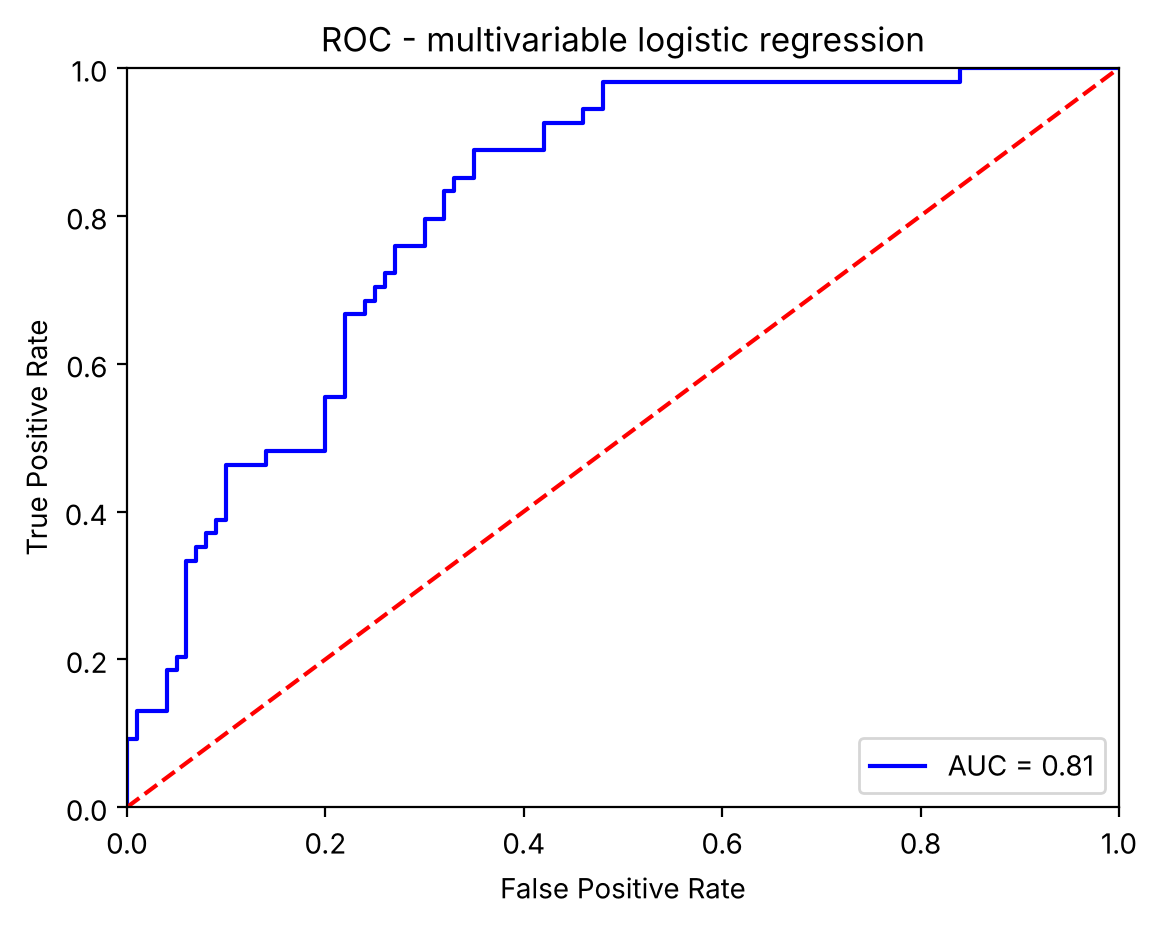

LR - 8 features (NOT normalized)
[[81 19]
 [27 27]]
Accuracy: 0.701 | Sensitivity: 0.500 | Specificity: 0.810 | PPV: 0.587 | F1: 0.540 | AUC: 0.811


In [16]:
# Compute the AUC and the ROC
plot_roc(y_test, y_prob_all, 'ROC - multivariable logistic regression')

# Same model WITHOUT normalizing the variables (just to see the effect)
lr_raw = LogisticRegression(max_iter=10000).fit(X_train, y_train)
_ = evaluate("LR - 8 features (NOT normalized)", lr_raw, X_test, y_test, store=False)

**Results of the multivariable model (8 normalized variables).** Test confusion matrix: TN = 81, FP = 19, FN = 28, TP = 26 → accuracy 0.695, sensitivity 0.481, specificity 0.81, PPV 0.578, F1 0.525 and **AUC = 0.812**. Compared with Age alone, the AUC improves a lot (0.71 → 0.81) and the sensitivity goes from 0.15 to 0.48, but the accuracy hardly increases (0.64 → 0.70) because with imbalanced classes the 0.5 threshold still leaves many diabetic patients undetected (28 false negatives).

**Normalized or not?** The model without normalization gives practically the same result (accuracy 0.701, sensitivity 0.50, AUC 0.811: a difference of one patient). As in the simple case the family of functions is the same; the small difference comes from the default L2 penalty, which is not scale invariant, because the variables have very different ranges (Insulin ~ hundreds, DiabetesPedigreeFunction ~ 0.5). We use the normalized data because it makes the **coefficients comparable** and the optimizer converge easily.

**Interpretation of the coefficients** (normalized variables; $e^{w}$ = odds ratio per +1 std, keeping the other variables fixed): **Glucose** has by far the largest effect ($w$ = 1.17, odds ×3.2), then **BMI** (0.68, ×2.0), **Pregnancies** (0.38, ×1.5), **DiabetesPedigreeFunction** (0.23, ×1.3) and Age (0.15, ×1.2). SkinThickness, Insulin and BloodPressure have coefficients ≈ 0 (|w| < 0.04) and even a negative sign for Insulin and BloodPressure, which has no clinical meaning: it is noise around zero.

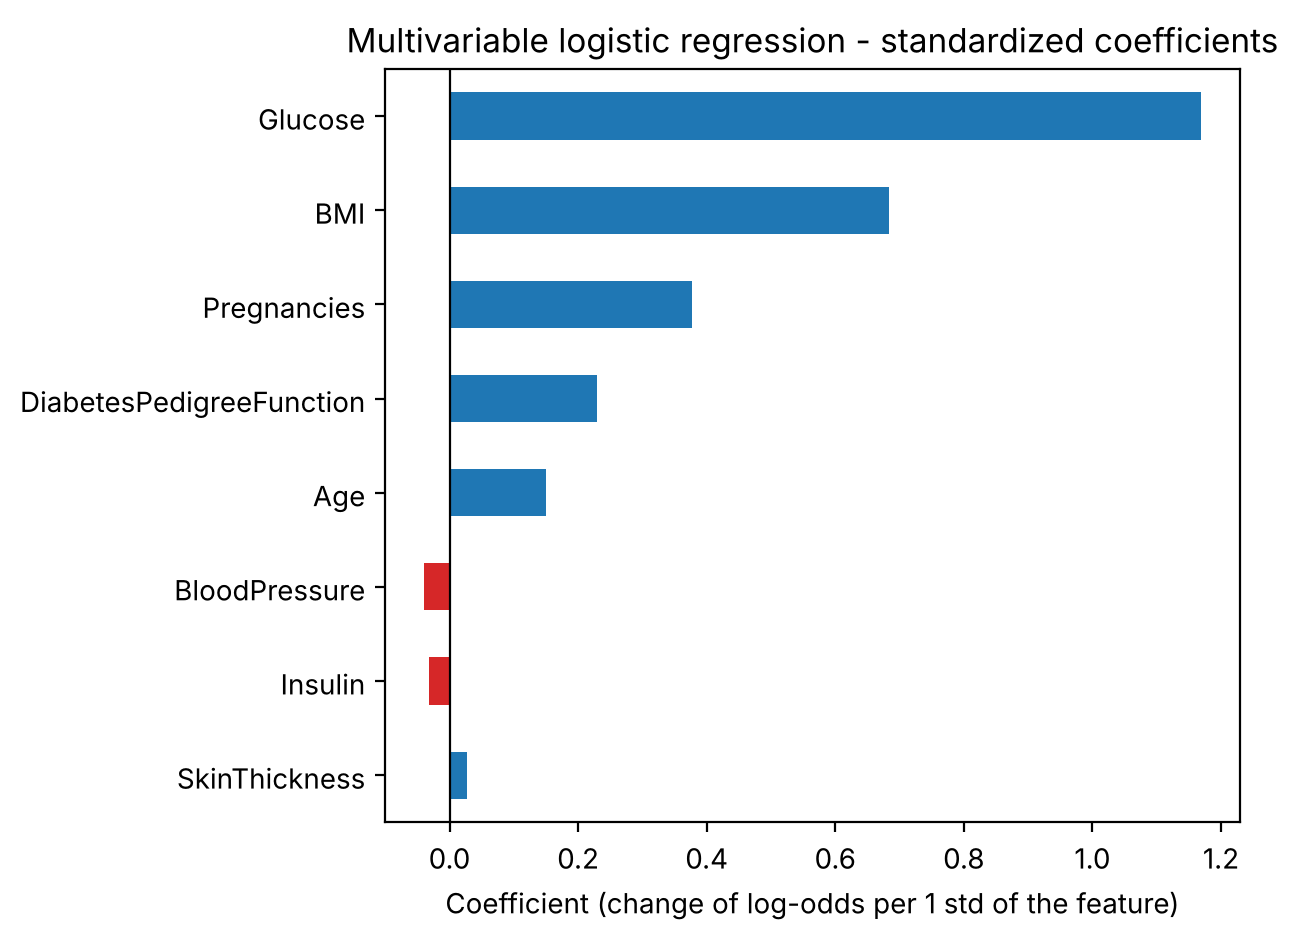

In [17]:
# Standardized coefficients
order = coefs['coef (normalized X)'].abs().sort_values().index
coefs.loc[order, 'coef (normalized X)'].plot(kind='barh', color=['tab:red' if v < 0 else 'tab:blue' for v in coefs.loc[order, 'coef (normalized X)']])
plt.axvline(0, color='k', lw=0.8)
plt.xlabel('Coefficient (change of log-odds per 1 std of the feature)')
plt.title('Multivariable logistic regression - standardized coefficients')
plt.tight_layout(); plt.show()

In [18]:
# How do the estimators and the figures of merit change with the number of variables?
# Variables are added one by one in order of importance (|standardized coefficient|)
ordered_features = list(coefs['coef (normalized X)'].abs().sort_values(ascending=False).index)
rows, coef_evolution = [], {}
for k in range(1, len(ordered_features) + 1):
    feats = ordered_features[:k]
    m = LogisticRegression().fit(X_train_std[feats], y_train)
    coef_evolution[k] = pd.Series(m.coef_[0], index=feats)
    # validation: 5-fold CV on the training set (the scaler is inside the pipeline -> no leakage between folds)
    cv_auc = cross_val_score(make_pipeline(StandardScaler(), LogisticRegression()), X_train[feats], y_train, cv=skf, scoring='roc_auc').mean()
    acc, sen, spe, ppv, f1, auc_te = classification_metrics(y_test, m.predict(X_test_std[feats]), m.predict_proba(X_test_std[feats])[:, 1])
    rows.append({'n variables': k, 'added variable': feats[-1], 'train AUC': roc_auc_score(y_train, m.predict_proba(X_train_std[feats])[:, 1]),
                 'CV AUC': cv_auc, 'test AUC': auc_te, 'test accuracy': acc, 'test sensitivity': sen})
nvars_table = pd.DataFrame(rows).set_index('n variables')
display(nvars_table.round(3))

,added variable,train AUC,CV AUC,test AUC,test accuracy,test sensitivity
n variables,,,,,,
1,Glucose,0.798,0.800,0.764,0.708,0.463
2,BMI,0.830,0.829,0.778,0.721,0.500
3,Pregnancies,0.843,0.842,0.803,0.701,0.556
4,DiabetesPedigreeFunction,0.850,0.847,0.811,0.695,0.500
5,Age,0.851,0.847,0.810,0.701,0.500
6,BloodPressure,0.851,0.847,0.812,0.701,0.481
7,Insulin,0.850,0.845,0.812,0.701,0.481
8,SkinThickness,0.850,0.844,0.812,0.695,0.481


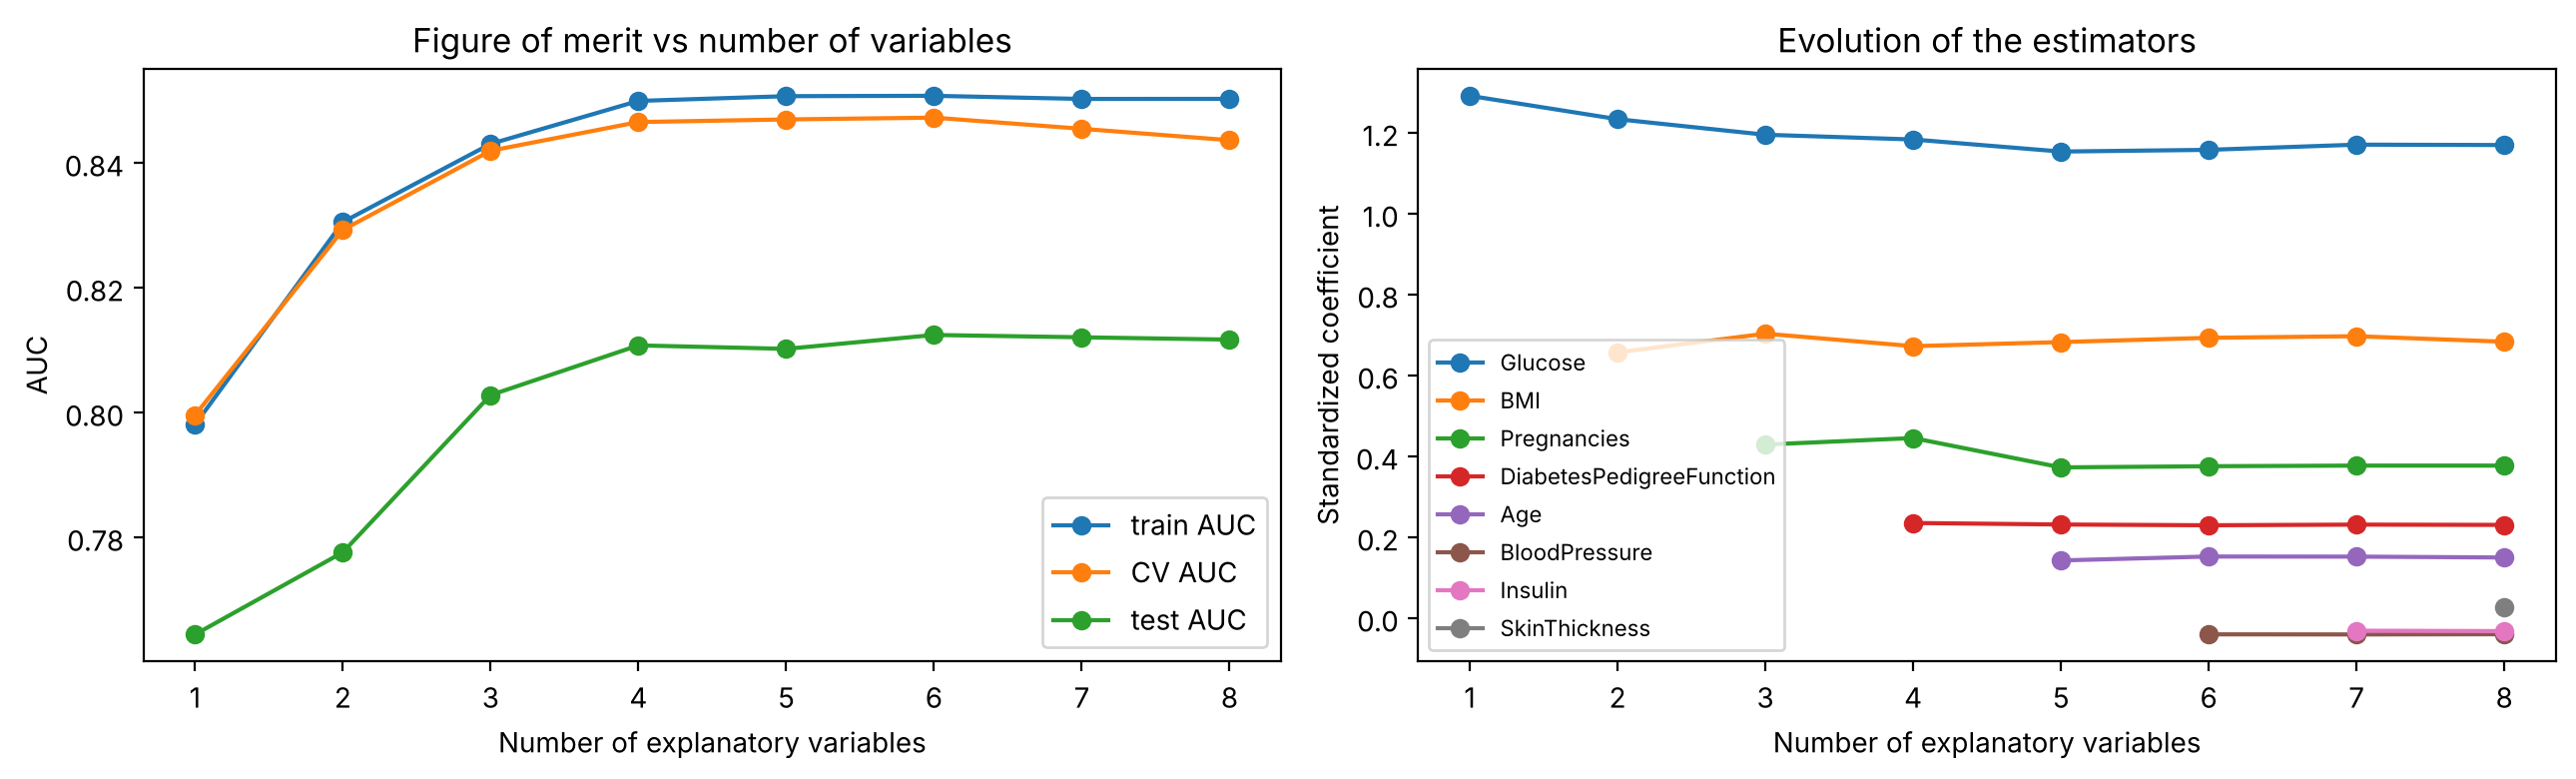

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
nvars_table[['train AUC', 'CV AUC', 'test AUC']].plot(marker='o', ax=axes[0])
axes[0].set_xlabel('Number of explanatory variables'); axes[0].set_ylabel('AUC'); axes[0].set_title('Figure of merit vs number of variables')
pd.DataFrame(coef_evolution).T[ordered_features].plot(marker='o', ax=axes[1])
axes[1].set_xlabel('Number of explanatory variables'); axes[1].set_ylabel('Standardized coefficient'); axes[1].set_title('Evolution of the estimators')
axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

In [20]:
# (3) Other approach: statsmodels gives p-values, so we can test which coefficients are significantly different from 0
import statsmodels.api as sm
logit = sm.Logit(y_train, sm.add_constant(X_train_std)).fit(disp=0)
print(logit.summary())

                           Logit Regression Results                           
Dep. Variable:                Outcome   No. Observations:                  614
Model:                          Logit   Df Residuals:                      605
Method:                           MLE   Df Model:                            8
Date:                Tue, 24 Nov 2026   Pseudo R-squ.:                  0.2991
Time:                        19:46:31   Log-Likelihood:                -278.22
converged:                       True   LL-Null:                       -396.97
Covariance Type:            nonrobust   LLR p-value:                 7.675e-47
                               coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------------
const                       -0.8774      0.110     -7.947      0.000      -1.094      -0.661
Pregnancies                  0.3848      0.124      3.111      0.002       0.142       0.

In [21]:
# Backward elimination using p-values: remove the least significant variable while its p-value > 0.05
feats_be = list(X.columns)
while True:
    r = sm.Logit(y_train, sm.add_constant(X_train_std[feats_be])).fit(disp=0)
    pvals = r.pvalues.drop('const')
    if pvals.max() <= 0.05:
        break
    print(f"Removing {pvals.idxmax():25s} (p-value = {pvals.max():.3f})")
    feats_be.remove(pvals.idxmax())
print("\nSelected features:", feats_be)

# Reduced model (selected features) evaluated on the test set
lr_be = LogisticRegression().fit(X_train_std[feats_be], y_train)
_ = evaluate("LR - backward elimination", lr_be, X_test_std[feats_be], y_test)

Removing SkinThickness             (p-value = 0.883)
Removing Insulin                   (p-value = 0.733)
Removing BloodPressure             (p-value = 0.697)
Removing Age                       (p-value = 0.246)

Selected features: ['Pregnancies', 'Glucose', 'BMI', 'DiabetesPedigreeFunction']
LR - backward elimination
[[80 20]
 [27 27]]
Accuracy: 0.695 | Sensitivity: 0.500 | Specificity: 0.800 | PPV: 0.574 | F1: 0.535 | AUC: 0.811


In [22]:
# Hard vs soft output: the hard output uses the threshold 0.5 on the soft output P(Outcome=1).
# What happens to sensitivity / specificity if we move the threshold? (8-feature model, test set)
rows = []
for thr in [0.6, 0.5, 0.4, 0.35, 0.3, 0.25]:
    pred = (y_prob_all >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    rows.append({'threshold': thr, 'accuracy': (tp + tn) / len(y_test), 'sensitivity': tp / (tp + fn), 'specificity': tn / (tn + fp), 'PPV': tp / (tp + fp)})
pd.DataFrame(rows).set_index('threshold').round(3)

,accuracy,sensitivity,specificity,PPV
threshold,,,,
0.60,0.721,0.463,0.86,0.641
0.50,0.695,0.481,0.81,0.578
0.40,0.727,0.630,0.78,0.607
0.35,0.734,0.685,0.76,0.607
0.30,0.734,0.796,0.70,0.589
0.25,0.721,0.852,0.65,0.568


**How do the estimators and the figures of merit change with the number of variables?** (table and plots above; variables added in order of |coefficient|)
* **Figure of merit:** the **CV AUC** grows quickly with the first four variables (0.800 → 0.829 → 0.842 → 0.847) and then stays flat (0.847, 0.847, 0.845, 0.844); the **training AUC** also saturates at 0.85 and the **test AUC** at 0.81. Adding the last four variables brings no gain, and the validation AUC even decreases slightly: they only add noise (variance) to the estimates. This is the usual *bias–variance* picture: a few informative variables are enough, more parameters do not help.
* **Estimators:** the coefficients change when other variables are included because the variables are **correlated**. For example, Glucose goes from 1.29 (alone) to 1.17 (8 variables) because part of its effect is shared with the other (correlated) variables, e.g. Insulin (corr. 0.42), and Pregnancies goes from 0.44 to 0.38 when Age is added (corr. Age–Pregnancies = 0.54). The coefficients of the three useless variables stay close to 0.

**Process to find the relevant features.** (1) Rank by |standardized coefficient| (comparable because of the normalization); (2) forward addition of variables checking the CV/test AUC; (3) **statistical significance with statsmodels** (Wald test of each coefficient; the global likelihood-ratio test has p = 7.7·10⁻⁴⁷, so the model as a whole is highly significant): significant at 5 %: Glucose (p ≈ 0), BMI (≈ 0), Pregnancies (p = 0.002) and DiabetesPedigreeFunction (p = 0.036); not significant: Age (0.25), BloodPressure (0.69), Insulin (0.73) and SkinThickness (0.88); (4) **backward elimination** with p > 0.05 removes SkinThickness → Insulin → BloodPressure → Age and keeps **Pregnancies, Glucose, BMI and DiabetesPedigreeFunction**. With those four variables the test results are the same as with the eight (AUC 0.811 vs 0.812, accuracy 0.695): the **most relevant features are Glucose, BMI, Pregnancies and DiabetesPedigreeFunction**, in this order of importance. Age is useful alone but redundant once Pregnancies is in the model (they are correlated), and Insulin (49 % of its values) and SkinThickness (30 %) were largely imputed in Lab 1, so they carry little real information.

**Hard vs soft output (threshold table).** The soft output allows us to choose the operating point: lowering the threshold from 0.5 to 0.35 increases the sensitivity from 0.48 to 0.69 (and even the accuracy, 0.695 → 0.734) at the cost of specificity (0.81 → 0.76); at 0.25 the sensitivity is 0.85 but the specificity drops to 0.65. Moving the threshold is moving along the ROC curve: the model (AUC) is the same, the clinical decision (how many false negatives we accept) is different. In a screening context we would prefer a threshold below 0.5, since a false negative (undetected diabetic) is more harmful than a false positive that is later discarded with another test.

## 4. Logistic regression with regularization

a) Indicate whether the performance obtained in the test set changes when Ridge or Lasso are considered.

b) Justify which characteristics are more relevant for these models.

In [23]:
# Logistic regression with regularization
from sklearn.model_selection import GridSearchCV

# C values and penalty. In scikit-learn C = 1/lambda (C small = strong regularization). l1 -> Lasso, l2 -> Ridge
# Regularization is NOT scale-invariant -> we use the normalized data
parameters = {"C": np.linspace(1e-4, 10, 100), "penalty": ["l1", "l2"]}

# Grid search with the training set only: 5-fold CV and the AUC as figure of merit
# (liblinear solver because it supports both l1 and l2)
log_regression = GridSearchCV(LogisticRegression(solver='liblinear'), parameters, scoring='roc_auc', cv=skf)

# Train using X_train
log_regression.fit(X_train_std, y_train)

# We show the best value of the parameter and the score
print(log_regression.best_params_)
print(log_regression.best_score_)

# The predicted output is obtained (the GridSearchCV object uses the best model found)
y_prob_grid = evaluate("LR - grid search (l1/l2)", log_regression, X_test_std, y_test)

{'C': np.float64(0.2021181818181818), 'penalty': 'l2'}
0.8445556478405315
LR - grid search (l1/l2)
[[80 20]
 [28 26]]
Accuracy: 0.688 | Sensitivity: 0.481 | Specificity: 0.800 | PPV: 0.565 | F1: 0.520 | AUC: 0.810


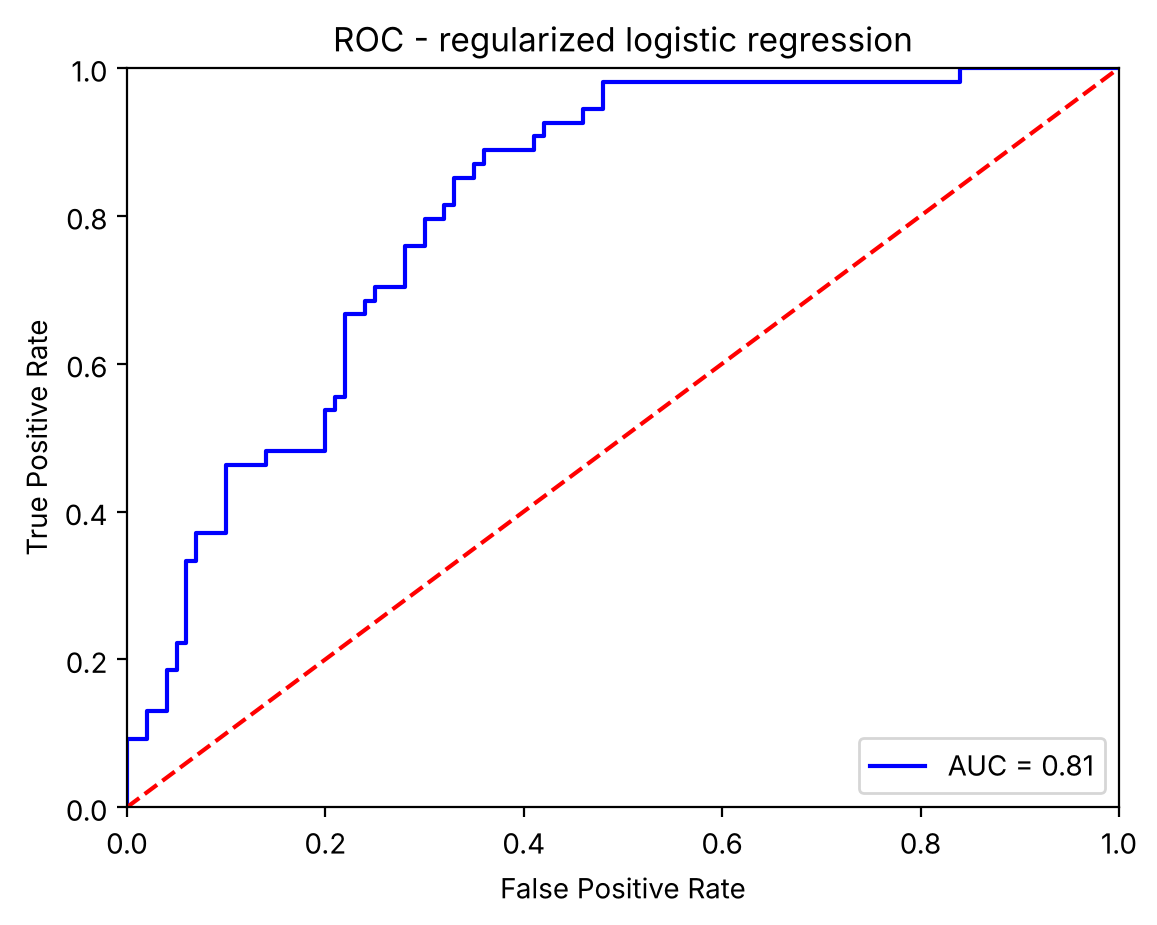

In [24]:
# ROC curve of the best regularized model
plot_roc(y_test, y_prob_grid, 'ROC - regularized logistic regression')

Ridge: best C = 0.202 | best CV AUC = 0.8446
LR - Ridge (best C by CV)
[[80 20]
 [28 26]]
Accuracy: 0.688 | Sensitivity: 0.481 | Specificity: 0.800 | PPV: 0.565 | F1: 0.520 | AUC: 0.810


Lasso: best C = 0.202 | best CV AUC = 0.8445
LR - Lasso (best C by CV)
[[81 19]
 [28 26]]
Accuracy: 0.695 | Sensitivity: 0.481 | Specificity: 0.810 | PPV: 0.578 | F1: 0.525 | AUC: 0.809


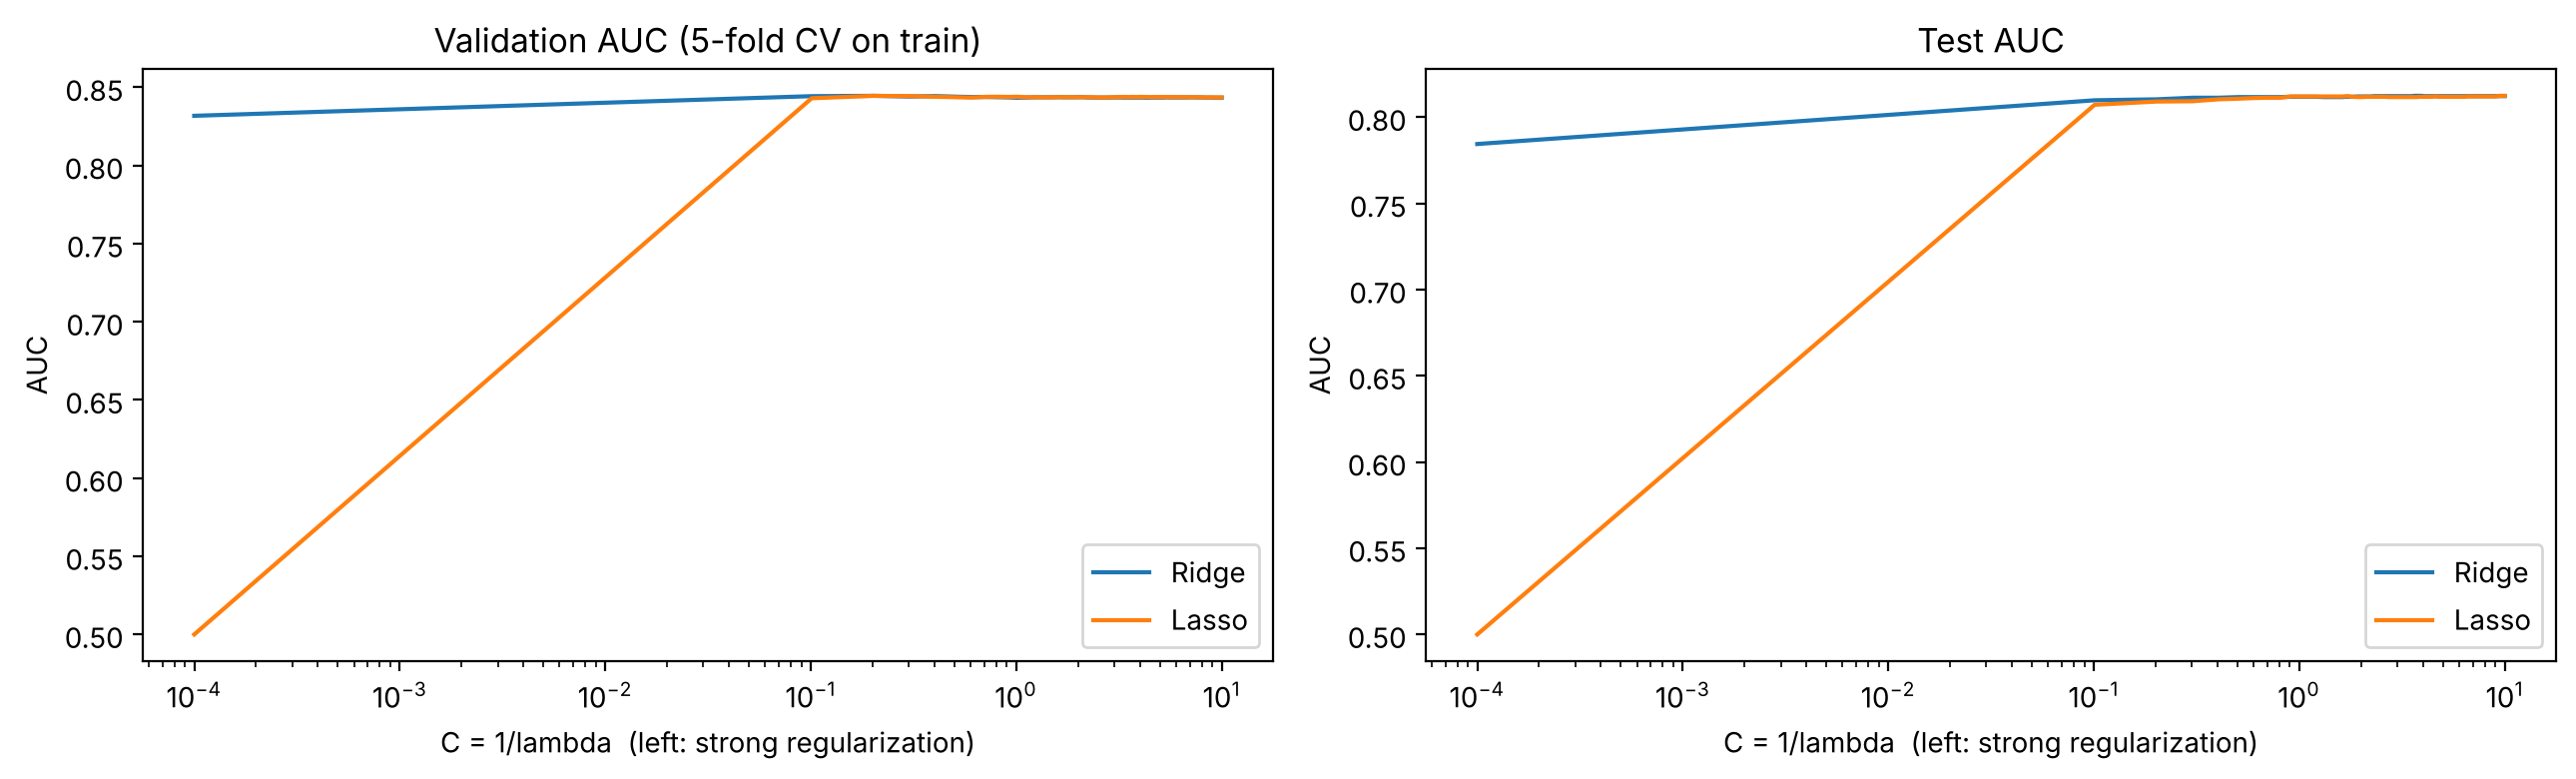

In [25]:
# Ridge (l2) and Lasso (l1) separately: best C by cross-validation, and how the figures of merit vary with C
Cs = np.linspace(1e-4, 10, 100)
reg_models, cv_curves, test_curves = {}, {}, {}
for pen, name in [('l2', 'Ridge'), ('l1', 'Lasso')]:
    g = GridSearchCV(LogisticRegression(solver='liblinear', penalty=pen), {"C": Cs}, scoring='roc_auc', cv=skf).fit(X_train_std, y_train)
    reg_models[name] = g
    cv_curves[name] = g.cv_results_['mean_test_score']
    test_curves[name] = [roc_auc_score(y_test, LogisticRegression(solver='liblinear', penalty=pen, C=c).fit(X_train_std, y_train).predict_proba(X_test_std)[:, 1]) for c in Cs]
    print(f"{name}: best C = {g.best_params_['C']:.3f} | best CV AUC = {g.best_score_:.4f}")
    _ = evaluate(f"LR - {name} (best C by CV)", g, X_test_std, y_test)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for name in ['Ridge', 'Lasso']:
    axes[0].semilogx(Cs, cv_curves[name], label=name)
    axes[1].semilogx(Cs, test_curves[name], label=name)
axes[0].set_title('Validation AUC (5-fold CV on train)'); axes[1].set_title('Test AUC')
for ax in axes: ax.set_xlabel('C = 1/lambda  (left: strong regularization)'); ax.set_ylabel('AUC'); ax.legend()
plt.tight_layout(); plt.show()

In [26]:
# Coefficients: no regularization vs Ridge vs Lasso, and how Lasso sets coefficients to 0 when C decreases
lr_noreg = LogisticRegression(C=1e10, max_iter=10000).fit(X_train_std, y_train)
comp_coefs = pd.DataFrame({'no regularization': lr_noreg.coef_[0],
                           'Ridge (best C)': reg_models['Ridge'].best_estimator_.coef_[0],
                           'Lasso (best C)': reg_models['Lasso'].best_estimator_.coef_[0]}, index=X.columns)
display(comp_coefs.round(3))

lasso_rows = {}
for c in [0.01, 0.02, 0.05, 0.1, 0.5, 1, 10]:
    m = LogisticRegression(solver='liblinear', penalty='l1', C=c).fit(X_train_std, y_train)
    lasso_rows[c] = pd.Series(m.coef_[0], index=X.columns)
lasso_table = pd.DataFrame(lasso_rows).T
lasso_table['n non-zero'] = (lasso_table != 0).sum(axis=1)
lasso_table.index.name = 'C'
display(lasso_table.round(3))

,no regularization,Ridge (best C),Lasso (best C)
Pregnancies,0.385,0.346,0.322
Glucose,1.192,1.083,1.093
BloodPressure,-0.046,-0.020,0.000
SkinThickness,0.020,0.044,0.000
Insulin,-0.042,-0.003,0.000
BMI,0.699,0.622,0.611
DiabetesPedigreeFunction,0.233,0.219,0.178
Age,0.148,0.150,0.110


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,n non-zero
C,,,,,,,,,
0.01,0.000,0.334,0.000,0.000,0.000,0.000,0.000,0.000,1
0.02,0.000,0.682,0.000,0.000,0.000,0.183,0.000,0.000,2
0.05,0.188,0.922,0.000,0.000,0.000,0.429,0.046,0.040,5
0.10,0.272,1.027,0.000,0.000,0.000,0.541,0.129,0.084,5
0.50,0.355,1.138,-0.000,0.006,0.000,0.654,0.210,0.126,7
1.00,0.369,1.163,-0.023,0.013,-0.017,0.676,0.221,0.137,8
10.00,0.383,1.190,-0.044,0.019,-0.039,0.697,0.232,0.148,8


**a) Does the test performance change with regularization?** Barely. The grid search (C from 10⁻⁴ to 10, penalties l1 and l2, 5-fold CV with AUC) selected **Ridge (l2) with C = 0.20** (CV AUC = 0.8446; Ridge and Lasso both have their optimum at C = 0.20, with CV AUC 0.8446 and 0.8445). On the test set: Ridge accuracy 0.688 / sensitivity 0.481 / AUC 0.810; Lasso 0.695 / 0.481 / 0.809; the unregularized model 0.695 / 0.481 / 0.812. The differences are of 0.003 in AUC, i.e. less than one patient out of 154: regularization **does not improve** this problem.

*Theory.* Regularization adds a penalty to the log-loss, $\min_{\mathbf w}\ -\ell(\mathbf w) + \frac{1}{C}\,\Omega(\mathbf w)$, with $\Omega = \|\mathbf w\|_2^2$ (Ridge) or $\|\mathbf w\|_1$ (Lasso). It increases a little the bias to reduce the variance, so it helps when the model has too many parameters for the data (many variables, collinearity, few observations). Here we have 8 variables and 614 patients (≈ 77 patients per parameter) and the unregularized model is already stable (train AUC 0.850, test AUC 0.812), so there is little variance to remove. Regularization would be much more important in Lab 2's polynomial model or with hundreds of variables.

**Influence of C** (see plots; for C → 0 the regularization is stronger): with very small C the coefficients are shrunk too much (underfitting): the test AUC drops to 0.787 for Ridge with C = 0.001 and to 0.5 for Lasso (all coefficients are 0, constant prediction); from C ≈ 0.05 the AUC is already 0.80–0.81 and for C ≥ 1 the models are indistinguishable from the unregularized one (0.812).

**b) Relevant features.** Ridge **shrinks** all the coefficients (Glucose 1.19 → 1.08, BMI 0.70 → 0.62) but keeps all of them non-zero; Lasso **sets some coefficients exactly to zero**, so it does *embedded feature selection*: with the optimal C it removes **BloodPressure, SkinThickness and Insulin**, the same variables that were not significant in the statsmodels analysis. Following the Lasso path when C decreases, the variables enter in the order **Glucose** (the only one left for C = 0.01) → **BMI** (C = 0.02) → Pregnancies, DiabetesPedigreeFunction and Age (C = 0.05): the same ranking as the forward-selection table. The relevant features are therefore Glucose, BMI, Pregnancies and DiabetesPedigreeFunction (Age is secondary).

## 5. Comparison of the results obtained with the different models


In [27]:
# Table with the performance on the TEST set of every model
comparison = pd.DataFrame({'Accuracy': accuracy, 'Sensitivity': sensitivity, 'Specificity': specificty, 'AUC': auc}, index=model_names)
comparison.round(3)

,Accuracy,Sensitivity,Specificity,AUC
LR - Age,0.636,0.148,0.90,0.710
LR - Glucose,0.708,0.463,0.84,0.764
LR - 8 features (normalized),0.695,0.481,0.81,0.812
LR - backward elimination,0.695,0.500,0.80,0.811
LR - grid search (l1/l2),0.688,0.481,0.80,0.810
LR - Ridge (best C by CV),0.688,0.481,0.80,0.810
LR - Lasso (best C by CV),0.695,0.481,0.81,0.809


Include in a table the performances of the test set obtained according to different figures of merit:

In view of the results obtained, answer, if possible, the following questions:

(a) Justify with which scheme of those analyzed you obtain better performances in the test set.

b) Justify the influence of the regularization parameter on the results obtained.

c) Justify reasonably if the fact of making a single partition of the cases in the training and test sets can influence the results obtained.

d) Starting from the original data, perform a new partition of the cases in the training and test sets. Select one of the classifiers analyzed (indicate the classifier chosen) and obtain again the confusion matrix and the evaluation measures. Comment on the results obtained.


Chosen classifier: normalized logistic regression with {'C': np.float64(0.2021181818181818), 'penalty': 'l2'}


,Accuracy,Sensitivity,Specificity,AUC
mean,0.765,0.560,0.876,0.839
std,0.024,0.060,0.033,0.025
min,0.708,0.463,0.800,0.775
max,0.818,0.685,0.950,0.871


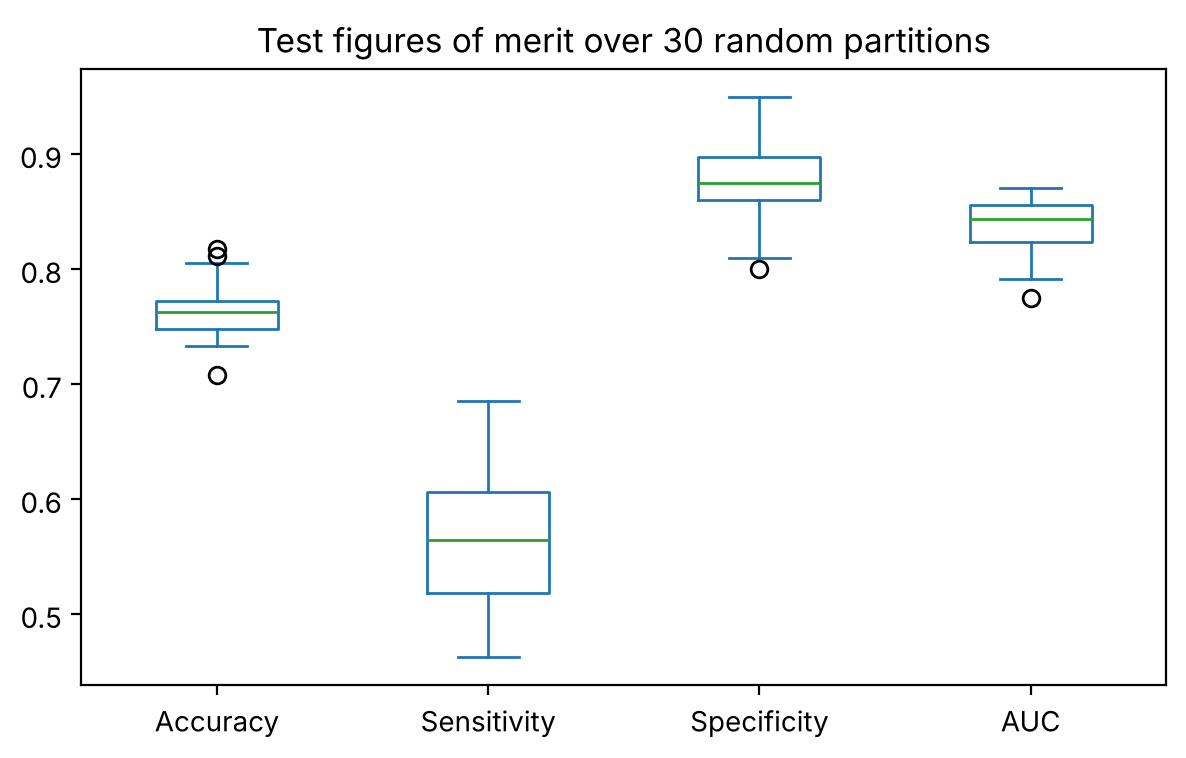

In [28]:
# (c) Influence of a single train/test partition: same model (the one chosen by CV in Section 4), 30 different partitions
chosen_params = log_regression.best_params_
print("Chosen classifier: normalized logistic regression with", chosen_params)

def chosen_model():
    return make_pipeline(StandardScaler(), LogisticRegression(solver='liblinear', **chosen_params))

rows = []
for seed in range(30):
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, random_state=seed, stratify=y)
    m = chosen_model().fit(Xtr, ytr)
    acc, sen, spe, ppv, f1, auc_ = classification_metrics(yte, m.predict(Xte), m.predict_proba(Xte)[:, 1])
    rows.append({'seed': seed, 'Accuracy': acc, 'Sensitivity': sen, 'Specificity': spe, 'AUC': auc_})
splits = pd.DataFrame(rows).set_index('seed')
display(splits.describe().loc[['mean', 'std', 'min', 'max']].round(3))
splits.plot(kind='box', figsize=(7, 4)); plt.title('Test figures of merit over 30 random partitions'); plt.show()

New partition (seed 7) - chosen LR
[[86 14]
 [21 33]]
Accuracy: 0.773 | Sensitivity: 0.611 | Specificity: 0.860 | PPV: 0.702 | F1: 0.653 | AUC: 0.845


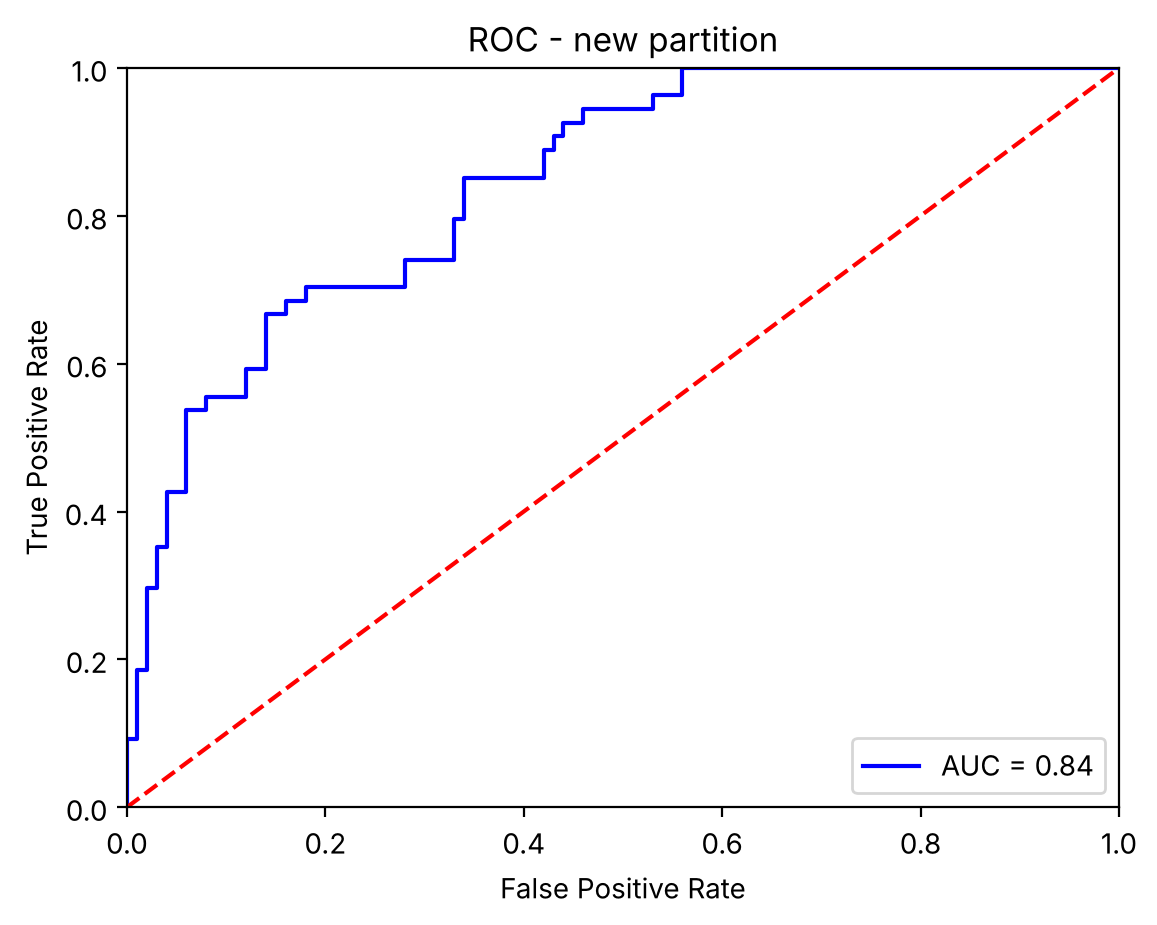

In [29]:
# (d) A new partition of the original data (random_state = 7). Chosen classifier: the same normalized
# logistic regression selected by CV (no re-tuning on the test set)
X_train2, X_test2, y_train2, y_test2 = train_test_split(X, y, test_size=0.2, random_state=7, stratify=y)
m2 = chosen_model().fit(X_train2, y_train2)
p2 = evaluate("New partition (seed 7) - chosen LR", m2, X_test2, y_test2, store=False)
plot_roc(y_test2, p2, 'ROC - new partition')

**a) Which scheme is best in the test set?** The univariate models are clearly worse (Age: AUC 0.71, sensitivity 0.15; Glucose: AUC 0.76, sensitivity 0.46). All the multivariable schemes (8 variables, backward elimination with 4 variables, Ridge, Lasso, grid search) are **equivalent**: AUC 0.809–0.812, accuracy 0.688–0.695, sensitivity 0.48–0.50. The differences are of one patient, far below the uncertainty of the estimation (see c), so we cannot say that one is better. As a final choice we would take a **multivariable, regularized (or parsimonious) logistic regression**, because it is as good as the others and more robust/simple: the model chosen by cross-validation (not by the test set) is Ridge with C = 0.20, and the 4-variable model is the most interpretable alternative.

**b) Influence of the regularization parameter.** Small C (strong regularization) → coefficients shrunk (Lasso: set to zero) and underfitting (test AUC 0.79 for Ridge with C = 0.001 and 0.5 for Lasso); large C → the solution converges to the unregularized logistic regression. In the middle there is a wide plateau (C from ≈ 0.05 to 10) where the AUC hardly changes, and the optimal C by CV (0.20) is in it. The best C is chosen with CV on the training set; choosing it with the test set would make the test estimate optimistic.

**c) Can a single train/test partition influence the results? Yes, a lot.** With the same classifier (Ridge, C = 0.20) and 30 random stratified partitions, the test figures of merit vary: accuracy 0.765 ± 0.024 (from 0.708 to 0.818), sensitivity 0.560 ± 0.060 (0.463 to 0.685), specificity 0.876 ± 0.033 and AUC 0.839 ± 0.025 (0.775 to 0.871). Our first partition (`random_state = 42`) turned out to be a "pessimistic" one: its accuracy (0.688) is lower than that of all the 30 random partitions. The reason is the small test set (154 patients, only 54 diabetic): the standard error of an accuracy of 0.75 with 154 patients is already $\sqrt{0.75\cdot0.25/154} \approx 0.035$, and the sensitivity is estimated with only 54 cases. The spread between partitions (±0.025 AUC) is larger than the differences among the schemes of the previous table (0.003), which confirms that those models cannot be ranked. To compare models reliably it is better to use cross-validation or repeated partitions and report mean ± standard deviation.

**d) New partition.** With another partition (`random_state = 7`) and the same classifier (normalized logistic regression, Ridge, C = 0.20, chosen by CV, no tuning on the new test set): TN = 86, FP = 14, FN = 21, TP = 33 → accuracy 0.773, sensitivity 0.611, specificity 0.86, PPV 0.702, F1 0.653, AUC 0.845. They are better than in the first partition (accuracy 0.688, AUC 0.810) but inside the range found with the 30 partitions, so the model did not change: the test sets are different. The conclusion is that the performance of the model should be reported as the average over many partitions (≈ 0.77 accuracy, 0.84 AUC, 0.56 sensitivity), and that the sensitivity at the 0.5 threshold is the weak point (it could be improved by lowering the threshold, as seen before).